In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import numpy as np

In [30]:
results = pd.read_csv("../results/beach_brightness_per_image_rgb.csv")
display(results.head())

results_stats = pd.read_csv("../results/beach_brightness_stats_rgb.csv")
display(results_stats.head())

,source,site,image_name,image_datetime,hs,tp,tide,roi_pixels,mean_rgb_sum,mean_rgb_sum_sq,luminance_sum,luminance_sum_sq,r_minus_b_mean,mean_rgb_image_mean,mean_rgb_image_std,luminance_image_mean,luminance_image_std
0,rgb,salinas,2016-06-19-11-24-23_S2_29TQJ_SALINAS_rgb.tif,2016-06-19 11:00:00,0.72,6.90,2.243,1134,2002297.000,3.614551e+09,1996512.25,3.598184e+09,296.822754,1765.693970,264.120087,1760.592773,270.767883
1,rgb,salinas,2017-08-13-11-24-33_S2_29TQJ_SALINAS_rgb.tif,2017-08-13 11:00:00,0.70,7.59,1.985,1134,2022851.375,3.682201e+09,2011996.75,3.647573e+09,309.049377,1783.819580,255.105560,1774.247559,261.916260
2,rgb,salinas,2017-09-19-11-18-08_S2_29TQJ_SALINAS_rgb.tif,2017-09-19 11:00:00,0.69,7.59,2.146,1134,2228877.500,4.777633e+09,2187631.50,4.608759e+09,82.062607,1965.500488,591.514038,1929.128296,585.342285
3,rgb,salinas,2018-06-14-11-21-12_S2_29TQJ_SALINAS_rgb.tif,2018-06-14 11:00:00,0.63,8.40,1.419,1134,1892341.250,3.250673e+09,1891474.50,3.251781e+09,318.761017,1668.731201,286.165253,1667.966919,292.263885
4,rgb,salinas,2018-08-15-11-18-26_S2_29TQJ_SALINAS_rgb.tif,2018-08-15 11:00:00,0.67,8.40,1.212,1134,1792854.000,3.059690e+09,1771606.00,3.008102e+09,215.702820,1581.000000,445.621185,1562.262817,460.415344


,source,site,n_images,n_pixels,mean_rgb_mean,mean_rgb_std,luminance_mean,luminance_std,r_minus_b_mean
0,rgb,puntal,28,45920,2313.087503,469.188190,2323.800076,476.537338,883.878994
1,rgb,salinas,24,25311,1736.036787,412.123595,1716.345546,417.057800,179.054872
2,rgb,all,52,71231,2108.040112,527.773980,2107.949090,541.044794,558.575553


In [31]:
# Comparativa Salinas vs Puntal
# En las siguientes celdas se comparan las métricas de brillo/luminosidad entre sitios,
# su relación con hs/tp/tide y la diferencia relativa (%) entre playas.

In [40]:
# Preparar datos y definir un subconjunto de métricas más interpretable
df = results.copy()
df["image_datetime"] = pd.to_datetime(df["image_datetime"], errors="coerce")

site_col = "site"
ocean_cols = ["hs", "tp", "tide"]

exclude_cols = {"source", "site", "image_name", "image_datetime", *ocean_cols, "roi_pixels"}
metric_cols = [c for c in df.columns if c not in exclude_cols]

# Asegurar que las métricas sean numéricas
for col in metric_cols + ocean_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Subconjunto recomendado: brillo medio + contraste espectral (sin métricas de desviación)
focus_metrics = [
    "mean_rgb_image_mean",
    "luminance_image_mean",
    "r_minus_b_mean",
]
focus_metrics = [m for m in focus_metrics if m in metric_cols]

print("Sitios:", sorted(df[site_col].dropna().unique().tolist()))
print("Métricas disponibles:", metric_cols)
print("Métricas recomendadas:", focus_metrics)
display(df[[site_col, "image_datetime", *ocean_cols, *focus_metrics]].head())

Sitios: ['puntal', 'salinas']
Métricas disponibles: ['mean_rgb_sum', 'mean_rgb_sum_sq', 'luminance_sum', 'luminance_sum_sq', 'r_minus_b_mean', 'mean_rgb_image_mean', 'mean_rgb_image_std', 'luminance_image_mean', 'luminance_image_std']
Métricas recomendadas: ['mean_rgb_image_mean', 'luminance_image_mean', 'r_minus_b_mean']


,site,image_datetime,hs,tp,tide,mean_rgb_image_mean,luminance_image_mean,r_minus_b_mean
0,salinas,2016-06-19 11:00:00,0.72,6.90,2.243,1765.693970,1760.592773,296.822754
1,salinas,2017-08-13 11:00:00,0.70,7.59,1.985,1783.819580,1774.247559,309.049377
2,salinas,2017-09-19 11:00:00,0.69,7.59,2.146,1965.500488,1929.128296,82.062607
3,salinas,2018-06-14 11:00:00,0.63,8.40,1.419,1668.731201,1667.966919,318.761017
4,salinas,2018-08-15 11:00:00,0.67,8.40,1.212,1581.000000,1562.262817,215.702820


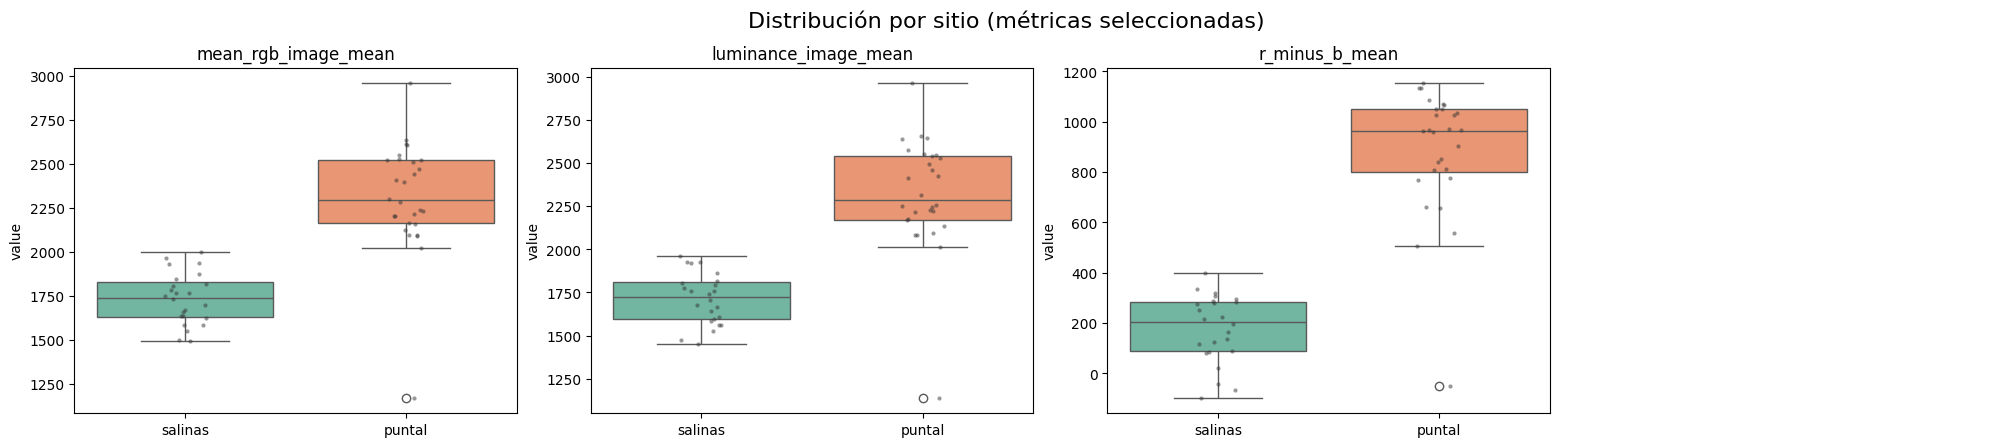

In [41]:
# Comparación directa entre sitios para métricas recomendadas
plot_df = df.melt(id_vars=[site_col], value_vars=focus_metrics,
                  var_name="metric", value_name="value").dropna()

n_metrics = len(focus_metrics)
ncols = 4
nrows = int(np.ceil(n_metrics / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)

for i, metric in enumerate(focus_metrics):
    ax = axes[i]
    d = plot_df[plot_df["metric"] == metric]
    sns.boxplot(data=d, x=site_col, y="value", ax=ax, hue=site_col, legend=False, palette="Set2")
    sns.stripplot(data=d, x=site_col, y="value", ax=ax, color="0.2", size=3, alpha=0.5)
    ax.set_title(metric)
    ax.set_xlabel("")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Distribución por sitio (métricas seleccionadas)", fontsize=16, y=1.08)
plt.show()

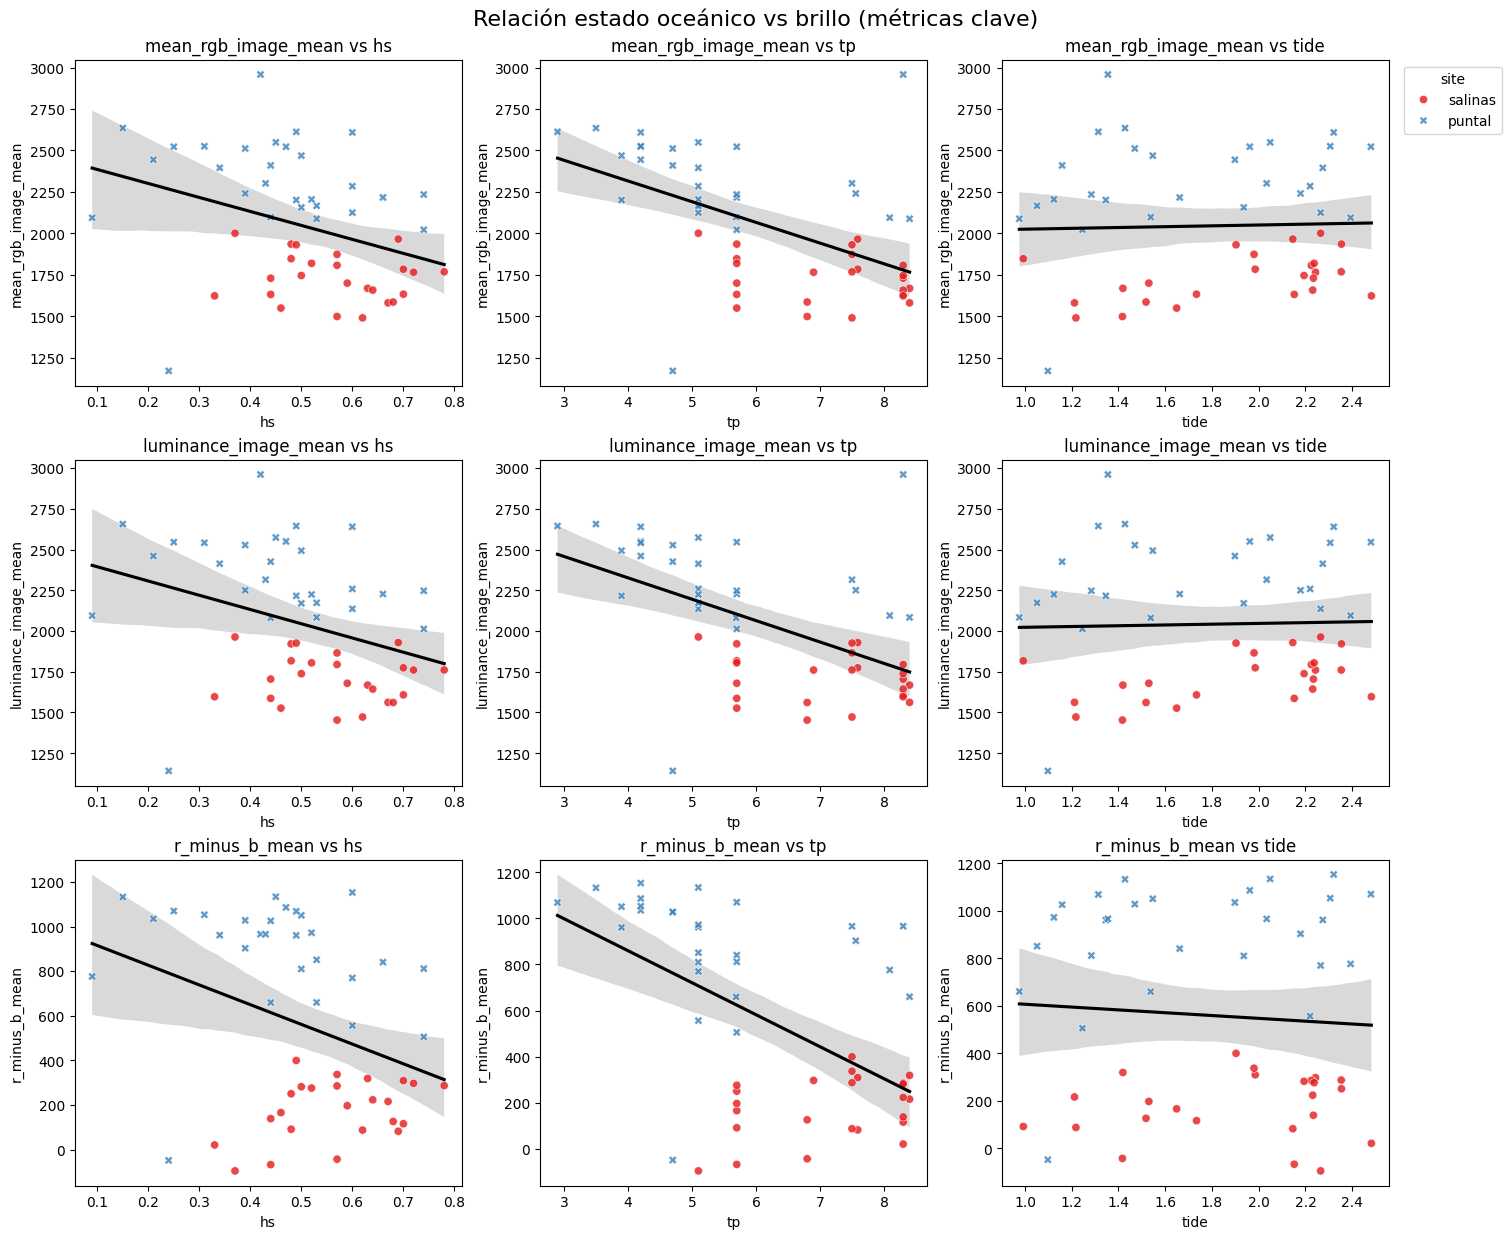

In [42]:
# Relación entre variables oceánicas y métricas clave
selected_metrics = [m for m in [
    "mean_rgb_image_mean",
    "luminance_image_mean",
    "r_minus_b_mean",
] if m in focus_metrics]

fig, axes = plt.subplots(len(selected_metrics), len(ocean_cols),
                         figsize=(5 * len(ocean_cols), 4 * len(selected_metrics)),
                         constrained_layout=True)

if len(selected_metrics) == 1:
    axes = np.array([axes])
if len(ocean_cols) == 1:
    axes = axes.reshape(len(selected_metrics), 1)

for i, metric in enumerate(selected_metrics):
    for j, ocean in enumerate(ocean_cols):
        ax = axes[i, j]
        sns.regplot(data=df, x=ocean, y=metric, scatter=False, ax=ax, color="black")
        sns.scatterplot(
            data=df, x=ocean, y=metric, hue=site_col, style=site_col,
            ax=ax, alpha=0.8, palette="Set1"
        )
        ax.set_title(f"{metric} vs {ocean}")
        if i == 0 and j == len(ocean_cols) - 1:
            ax.legend(title="site", bbox_to_anchor=(1.02, 1), loc="upper left")
        else:
            leg = ax.get_legend()
            if leg is not None:
                leg.remove()

plt.suptitle("Relación estado oceánico vs brillo (métricas clave)", fontsize=16, y=1.02)
plt.show()

,mean_rgb_image_mean,luminance_image_mean,r_minus_b_mean
site,,,
puntal,"2,313.088","2,323.800",883.879
salinas,"1,733.105","1,713.271",179.055


,puntal_vs_salinas_pct,salinas_vs_puntal_pct
r_minus_b_mean,+393.64%,-79.74%
luminance_image_mean,+35.64%,-26.27%
mean_rgb_image_mean,+33.46%,-25.07%


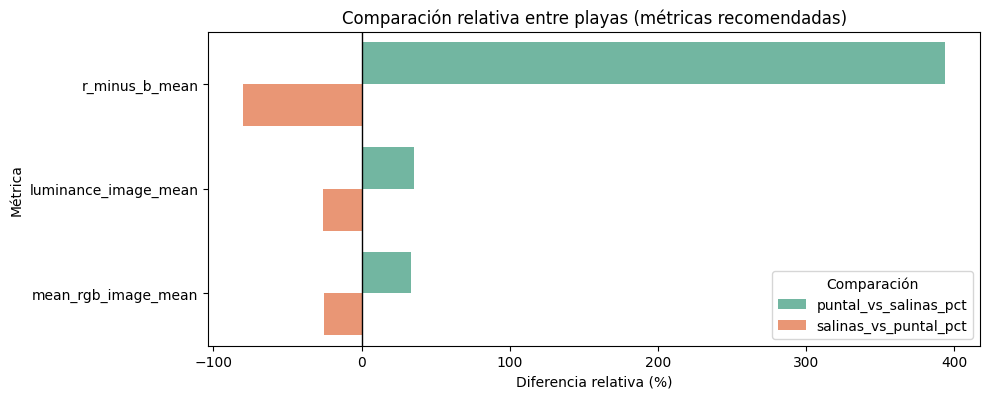

In [43]:
# Comparación relativa (%) entre playas para métricas recomendadas
mean_by_site = df.groupby(site_col)[focus_metrics].mean(numeric_only=True)
display(mean_by_site.style.format('{:,.3f}'))

sites = sorted(mean_by_site.index.tolist())
if len(sites) == 2:
    s1, s2 = sites[0], sites[1]
    rel = pd.DataFrame({
        f"{s1}_vs_{s2}_pct": (mean_by_site.loc[s1] / mean_by_site.loc[s2] - 1) * 100,
        f"{s2}_vs_{s1}_pct": (mean_by_site.loc[s2] / mean_by_site.loc[s1] - 1) * 100,
    })
    rel = rel.sort_values(by=f"{s1}_vs_{s2}_pct", key=lambda s: s.abs(), ascending=False)
    display(rel.style.format('{:+.2f}%'))

    rel_plot = rel.reset_index().melt(id_vars="index", var_name="comparison", value_name="pct")
    rel_plot = rel_plot.rename(columns={"index": "metric"})

    plt.figure(figsize=(10, 0.7 * len(focus_metrics) + 2))
    sns.barplot(data=rel_plot, x="pct", y="metric", hue="comparison", palette="Set2")
    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Diferencia relativa (%)")
    plt.ylabel("Métrica")
    plt.title("Comparación relativa entre playas (métricas recomendadas)")
    plt.legend(title="Comparación")
    plt.tight_layout()
    plt.show()
else:
    print("La comparación relativa en % requiere exactamente dos sitios.")

,metric,median_puntal,median_salinas,median_diff_puntal_minus_salinas,mannwhitney_u,p_value,cliffs_delta,abs_cliffs_delta,p_value_fdr_bh,significant_0_05
2,r_minus_b_mean,963.450,206.228,+757.222,650.000000,8.691e-09,+0.935,0.935,1.079e-08,True
0,mean_rgb_image_mean,2293.145,1737.898,+555.247,648.000000,1.079e-08,+0.929,0.929,1.079e-08,True
1,luminance_image_mean,2286.843,1721.605,+565.237,648.000000,1.079e-08,+0.929,0.929,1.079e-08,True


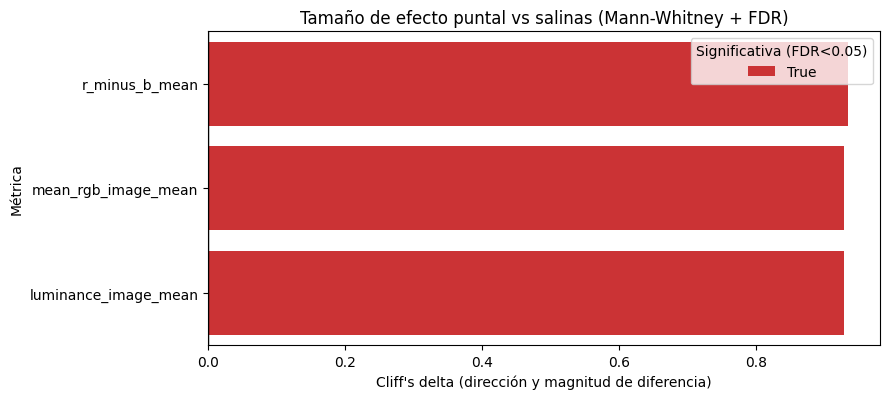

In [44]:
# Test estadístico entre playas para métricas recomendadas
from scipy.stats import mannwhitneyu

def cliffs_delta(x, y):
    # Tamaño de efecto no paramétrico: probabilidad de superioridad entre grupos
    x = np.asarray(x)
    y = np.asarray(y)
    gt = sum(np.sum(xi > y) for xi in x)
    lt = sum(np.sum(xi < y) for xi in x)
    return (gt - lt) / (len(x) * len(y))

def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / (np.arange(1, n + 1))
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty_like(q)
    out[order] = q
    return out

sites = sorted(df[site_col].dropna().unique().tolist())
if len(sites) != 2:
    print("Se requieren exactamente dos sitios para esta comparación.")
else:
    s1, s2 = sites[0], sites[1]
    rows = []
    for metric in focus_metrics:
        x = df.loc[df[site_col] == s1, metric].dropna().values
        y = df.loc[df[site_col] == s2, metric].dropna().values
        if len(x) < 3 or len(y) < 3:
            continue
        stat, p = mannwhitneyu(x, y, alternative="two-sided")
        delta = cliffs_delta(x, y)
        rows.append({
            "metric": metric,
            f"median_{s1}": np.median(x),
            f"median_{s2}": np.median(y),
            f"median_diff_{s1}_minus_{s2}": np.median(x) - np.median(y),
            "mannwhitney_u": stat,
            "p_value": p,
            "cliffs_delta": delta,
            "abs_cliffs_delta": abs(delta),
        })

    stats_df = pd.DataFrame(rows)
    if not stats_df.empty:
        stats_df["p_value_fdr_bh"] = bh_fdr(stats_df["p_value"].values)
        stats_df["significant_0_05"] = stats_df["p_value_fdr_bh"] < 0.05
        stats_df = stats_df.sort_values(["significant_0_05", "abs_cliffs_delta", "p_value_fdr_bh"], ascending=[False, False, True])
        display(stats_df.style.format({
            "p_value": "{:.3e}",
            "p_value_fdr_bh": "{:.3e}",
            "cliffs_delta": "{:+.3f}",
            "abs_cliffs_delta": "{:.3f}",
            f"median_{s1}": "{:.3f}",
            f"median_{s2}": "{:.3f}",
            f"median_diff_{s1}_minus_{s2}": "{:+.3f}",
        }))

        plt.figure(figsize=(9, 0.7 * len(stats_df) + 2))
        sns.barplot(data=stats_df, x="cliffs_delta", y="metric", hue="significant_0_05", palette="Set1")
        plt.axvline(0, color="black", linewidth=1)
        plt.xlabel("Cliff's delta (dirección y magnitud de diferencia)")
        plt.ylabel("Métrica")
        plt.title(f"Tamaño de efecto {s1} vs {s2} (Mann-Whitney + FDR)")
        plt.legend(title="Significativa (FDR<0.05)")
        plt.tight_layout()
        plt.show()
    else:
        print("No hay datos suficientes para ejecutar los test.")